# Works periods and imputation of the ages at first and last work

In [1]:
import sys
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
OUTPUT_PATH = Path('../../data/enriched_parquets/individual_work_dates.parquet')  # datamodel shape
SAVE = False  # True writes OUTPUT_PATH
KNOWN_PRECISIONS = ['day', 'month', 'year', 'decade']  # dates precise to the year or the decade
MID_DECADE = 5  # a decade counts as its middle year
LIFETIME = 100  # years: the longest span of a single life
OCCUPATIONS = list(OCCUPATION_COLORS)  # the four occupational categories
ALL = 'All'  # no recorded occupation
GROUPS = [*OCCUPATIONS, ALL]
MEASURES = ['first', 'last']
AGE_RANGE = (10, 100)  # plausible ages at the first and the last work, in years
FIRST_CENTURY = -800  # earliest births the ages are learnt from
LAST_BIRTH_YEAR = 1950  # born later: may not have done their last work yet, neither learnt from nor imputed
MIN_COHORT = 10  # a smaller cohort takes the nearest century
CENTURY = 100  # years
TEST_SHARE = 0.2  # held-out share of the individuals with a work period
WITHIN = 10  # years between the imputed and the true year
MODELS = {
    'global median': [],
    'median by century of birth': ['century'],
    'median by occupation': ['occupation'],
    'median by century of birth × occupation': ['century', 'occupation'],
}
TYCHO_BRAHE = 'Q36620'
OVERALL = 'Overall'  # every individual, whatever the occupation
SPLIT_YEAR = 1500  # births before and after, in the second work-period figure
SEED = 42

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Birth and death years from Wikidata only (no estimated date), precise to the year or the decade.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
people = con.sql('''
    WITH held AS (
        SELECT entity.qid AS qid, unnest(occupation).entity.qid AS occupation_qid, generate_subscripts(occupation, 1) AS position
        FROM individual
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation AS occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN occupation ON occupation.entity.qid = held.occupation_qid
        WHERE list_contains($occupations, occupation.meta_occupation)
        GROUP BY ALL
    ),
    main_occupation AS (
        SELECT qid, occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    ),
    dates AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS birth_year,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS death_year,
               coalesce(entity.label_en, entity.label_non_en) AS name,
               len(sitelink) AS sitelinks
        FROM individual
    )
    SELECT dates.qid, dates.name, dates.sitelinks,
           coalesce(main_occupation.occupation, $all) AS occupation,
           dates.birth_year, dates.death_year,
           dates.qid IN (SELECT qid FROM individual_work) AS has_works
    FROM dates
    LEFT JOIN main_occupation ON main_occupation.qid = dates.qid
''', params={'known': KNOWN_PRECISIONS, 'occupations': OCCUPATIONS, 'all': ALL}).pl()
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals, {people["has_works"].sum():,} with works')
people.sample(5, seed=SEED)

13,002,897 individuals, 2,890,465 with works


qid,name,sitelinks,occupation,birth_year,death_year,has_works
str,str,i64,str,i64,i64,bool
"""Q80676227""","""María Dolores Granado Castro""",0,"""Discovery/Science""",null,null,true
"""Q130613231""","""Katherine McKenna""",0,"""All""",null,null,false
"""Q133885947""","""Josef Musil""",0,"""Leadership""",1869,null,false
"""Q65695862""","""Jacques Kuiper""",0,"""Sports/Games""",null,null,false
"""Q7971388""","""Waseem Abbas""",4,"""Culture""",1957,null,true


### Work dates
A work's date is its inception (P571), else its publication date (P577), precise to the year or the decade.

In [3]:
con.register('lifetime', people.select('qid', 'birth_year', 'death_year').to_arrow())
work_dates = con.sql('''
    WITH dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               list_contains($known, work.inception.precision) AS from_inception,
               CASE WHEN list_contains($known, work.inception.precision) THEN work.inception ELSE work.publication_date END AS date
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE list_contains($known, work.inception.precision) OR list_contains($known, work.publication_date.precision)
    )
    SELECT dated.qid, dated.work_qid,
           CASE WHEN dated.from_inception THEN 'inception' ELSE 'publication' END AS source,
           dated.date.year + CASE WHEN dated.date.precision = 'decade' THEN $mid_decade ELSE 0 END AS year,
           lifetime.birth_year, lifetime.death_year
    FROM dated
    JOIN lifetime ON lifetime.qid = dated.qid
''', params={'known': KNOWN_PRECISIONS, 'mid_decade': MID_DECADE}).pl()
print(f'{work_dates.height:,} work dates for {work_dates["qid"].n_unique():,} individuals')
work_dates.sample(5, seed=SEED)

36,804,752 work dates for 2,773,370 individuals


qid,work_qid,source,year,birth_year,death_year
str,str,str,i64,i64,i64
"""Q91622774""","""Q91622779""","""publication""",2019,1985,null
"""Q114427964""","""Q88931515""","""publication""",2018,null,null
"""Q936710""","""Q136029539""","""inception""",1889,1861,1942
"""Q39756841""","""Q37013304""","""publication""",2008,1960,null
"""Q96765520""","""Q96765522""","""publication""",2020,null,null


## Cleaning of the work dates
1. Individuals without birth or death whose dated works carry only publication dates are excluded: a publication date may be a much later edition.
2. A work date must fall inside the lifetime: birth to death, or within 100 years of a single birth or death.
3. For individuals without birth or death, a publication date more than 100 years from their earliest inception is removed.
4. Individuals without birth or death whose inception dates alone span more than 100 years lose all their work dates.

In [4]:
has_lifetime = pl.col('birth_year').is_not_null() | pl.col('death_year').is_not_null()
inception_years = pl.col('year').filter(pl.col('source') == 'inception')
lower = pl.coalesce('birth_year', pl.col('death_year') - LIFETIME)
upper = pl.coalesce('death_year', pl.col('birth_year') + LIFETIME)
RULES = {
    '1. publication dates only, no birth or death': ~has_lifetime & inception_years.min().over('qid').is_null(),
    '2. outside the lifetime': ~pl.col('year').is_between(lower, upper),
    '3. publication over 100 years from the earliest inception': ~has_lifetime & (pl.col('source') == 'publication') & ((pl.col('year') - inception_years.min().over('qid')).abs() > LIFETIME),
    '4. inceptions spanning over 100 years': ~has_lifetime & ((inception_years.max() - inception_years.min()).over('qid') > LIFETIME),
}

kept = work_dates
log = [{'step': 'dated works', 'work dates': kept.height, 'individuals': kept['qid'].n_unique()}]
for step, dropped in RULES.items():
    kept = kept.filter(~dropped.fill_null(False))
    log.append({'step': step, 'work dates': kept.height, 'individuals': kept['qid'].n_unique()})
pl.DataFrame(log)

step,work dates,individuals
str,i64,i64
"""dated works""",36804752,2773370
"""1. publication dates only, no …",9637863,599887
"""2. outside the lifetime""",9479750,584832
"""3. publication over 100 years …",9478965,584832
"""4. inceptions spanning over 10…",9478728,584786


### Work periods
The span between the earliest and the latest cleaned work date; the ages are counted from the Wikidata birth year.

In [5]:
periods = (
    kept.group_by('qid')
    .agg(pl.len().alias('work_dates'), pl.col('year').min().alias('first_year'), pl.col('year').max().alias('last_year'))
    .join(people, on='qid')
    .with_columns(
        (pl.col('first_year') - pl.col('birth_year')).alias('age_at_first_work'),
        (pl.col('last_year') - pl.col('birth_year')).alias('age_at_last_work'),
        (pl.col('birth_year') // CENTURY * CENTURY).alias('century'),
    )
)
assert periods['qid'].is_unique().all() and (periods['first_year'] <= periods['last_year']).all()
print(f'{periods.height:,} individuals with a work period')
periods.sample(5, seed=SEED)

584,786 individuals with a work period


qid,work_dates,first_year,last_year,name,sitelinks,occupation,birth_year,death_year,has_works,age_at_first_work,age_at_last_work,century
str,u32,i64,i64,str,i64,str,i64,i64,bool,i64,i64,i64
"""Q69542644""",4,1985,2016,"""A. Douglas Stone""",4,"""Discovery/Science""",1954,null,true,31,62,1900
"""Q18921392""",1,1935,1935,"""Melton Barker""",1,"""Culture""",1903,1977,true,32,32,1900
"""Q976428""",44,1976,2022,"""Claudio Fragasso""",10,"""Culture""",1951,null,true,25,71,1900
"""Q5742656""",283,1991,2006,"""Lennart Fremling""",4,"""Leadership""",1946,2013,true,45,60,1900
"""Q626325""",2,2009,2017,"""JeA""",13,"""Culture""",1981,null,true,28,36,1900


### Example: Tycho Brahe
Astronomiae Instauratae Progymnasmata (1602), published by Kepler after Brahe's death in 1601, is removed.

In [6]:
brahe = (
    work_dates.filter(pl.col('qid') == TYCHO_BRAHE)
    .join(kept.filter(pl.col('qid') == TYCHO_BRAHE).select('work_qid', 'year', pl.lit(True).alias('kept')), on=['work_qid', 'year'], how='left')
    .with_columns(pl.col('kept').fill_null(False))
)
labels = con.sql('SELECT entity.qid AS work_qid, entity.label_en AS work FROM work WHERE list_contains($qids, entity.qid)', params={'qids': brahe['work_qid'].to_list()}).pl()
brahe_period = periods.filter(pl.col('qid') == TYCHO_BRAHE)
assert brahe_period.select('first_year', 'last_year').row(0) == (1573, 1598), brahe_period
brahe.join(labels, on='work_qid', how='left').select('work', 'source', 'year', 'kept').sort('year')

work,source,year,kept
str,str,i64,bool
"""De Nova Stella""","""publication""",1573,true
"""De Mundi aetherei recentioribu…","""inception""",1588,true
"""Astronomiae Instauratae Mechan…","""publication""",1598,true
"""Astronomiae Instauratae Progym…","""publication""",1602,false


### First and last works of the best-known individual of each century of birth
The individual with the most Wikipedia pages, and Tycho Brahe.

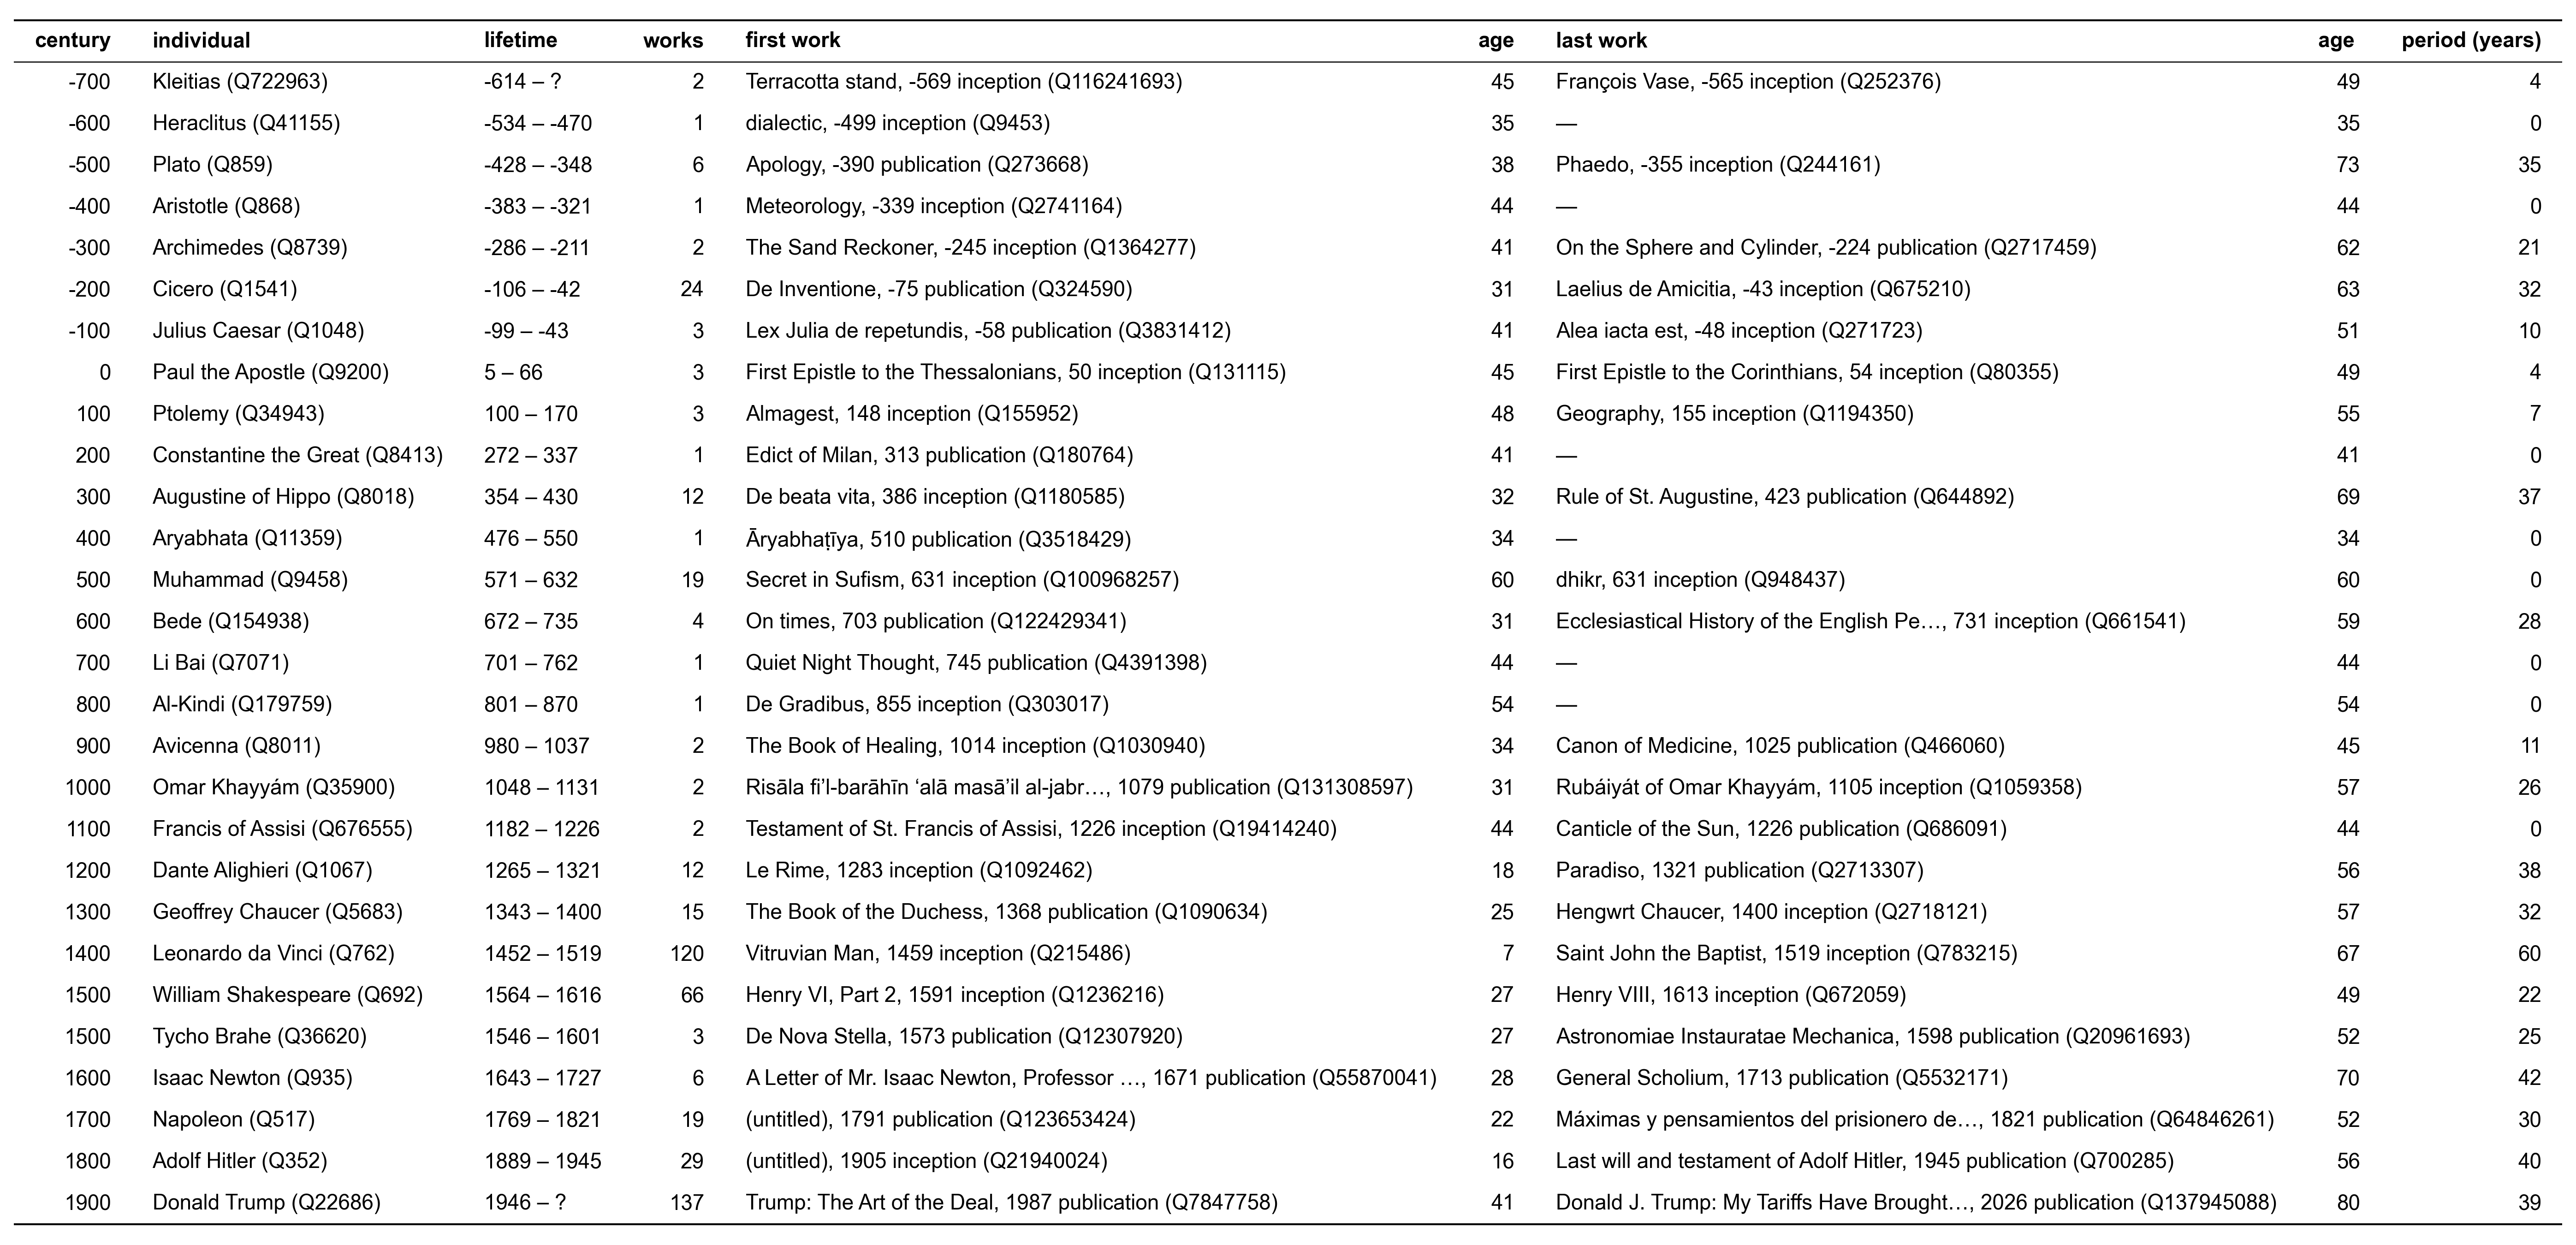

In [7]:
def best_known_per_century(frame):
    """The individual with the most Wikipedia pages in every century of birth, plus Tycho Brahe."""
    if 'name' not in frame.columns:
        frame = frame.join(people.select('qid', 'name', 'sitelinks'), on='qid')
    return (
        frame.filter(pl.col('birth_year').is_between(FIRST_CENTURY, LAST_BIRTH_YEAR))
        .sort('sitelinks', 'qid', descending=[True, False])
        .filter((pl.int_range(pl.len()).over('century') == 0) | (pl.col('qid') == TYCHO_BRAHE))
        .sort('century', pl.col('qid') == TYCHO_BRAHE)
    )


def first_and_last_works(qids):
    """The earliest and the latest cleaned work of each individual, with the works' labels."""
    rows = kept.filter(pl.col('qid').is_in(qids.implode())).sort('qid', 'year', 'work_qid')
    ends = rows.group_by('qid').agg(*[pl.col(c).first().alias(f'first_{c}') for c in ('work_qid', 'source')], *[pl.col(c).last().alias(f'last_{c}') for c in ('work_qid', 'source')])
    labels = con.sql("SELECT entity.qid AS work_qid, coalesce(entity.label_en, entity.label_non_en, '(untitled)') AS label FROM work WHERE list_contains($qids, entity.qid)",
                     params={'qids': [*ends['first_work_qid'], *ends['last_work_qid']]}).pl()
    for end in ('first', 'last'):
        ends = ends.join(labels.rename({'work_qid': f'{end}_work_qid', 'label': f'{end}_label'}), on=f'{end}_work_qid', how='left')
    return ends


def work_text(end):
    label = pl.col(f'{end}_label')
    label = pl.when(label.str.len_chars() > 40).then(label.str.slice(0, 40) + '…').otherwise(label)
    return pl.format('{}, {} {} ({})', label, f'{end}_year', f'{end}_source', f'{end}_work_qid')


def individual_columns():
    return [
        pl.col('century').cast(pl.String),
        pl.format('{} ({})', 'name', 'qid').alias('individual'),
        pl.format('{} – {}', pl.col('birth_year').cast(pl.String).fill_null('?'), pl.col('death_year').cast(pl.String).fill_null('?')).alias('lifetime'),
    ]


examples = best_known_per_century(periods)
examples = examples.join(first_and_last_works(examples['qid']), on='qid', maintain_order='left')
show_table(examples.select(
    *individual_columns(),
    pl.col('work_dates').alias('works'),
    work_text('first').alias('first work'),
    pl.col('age_at_first_work').alias('age'),
    pl.when(pl.col('work_dates') > 1).then(work_text('last')).alias('last work'),
    pl.col('age_at_last_work').alias('age '),
    (pl.col('last_year') - pl.col('first_year')).alias('period (years)'),
))

### Individuals with a work period

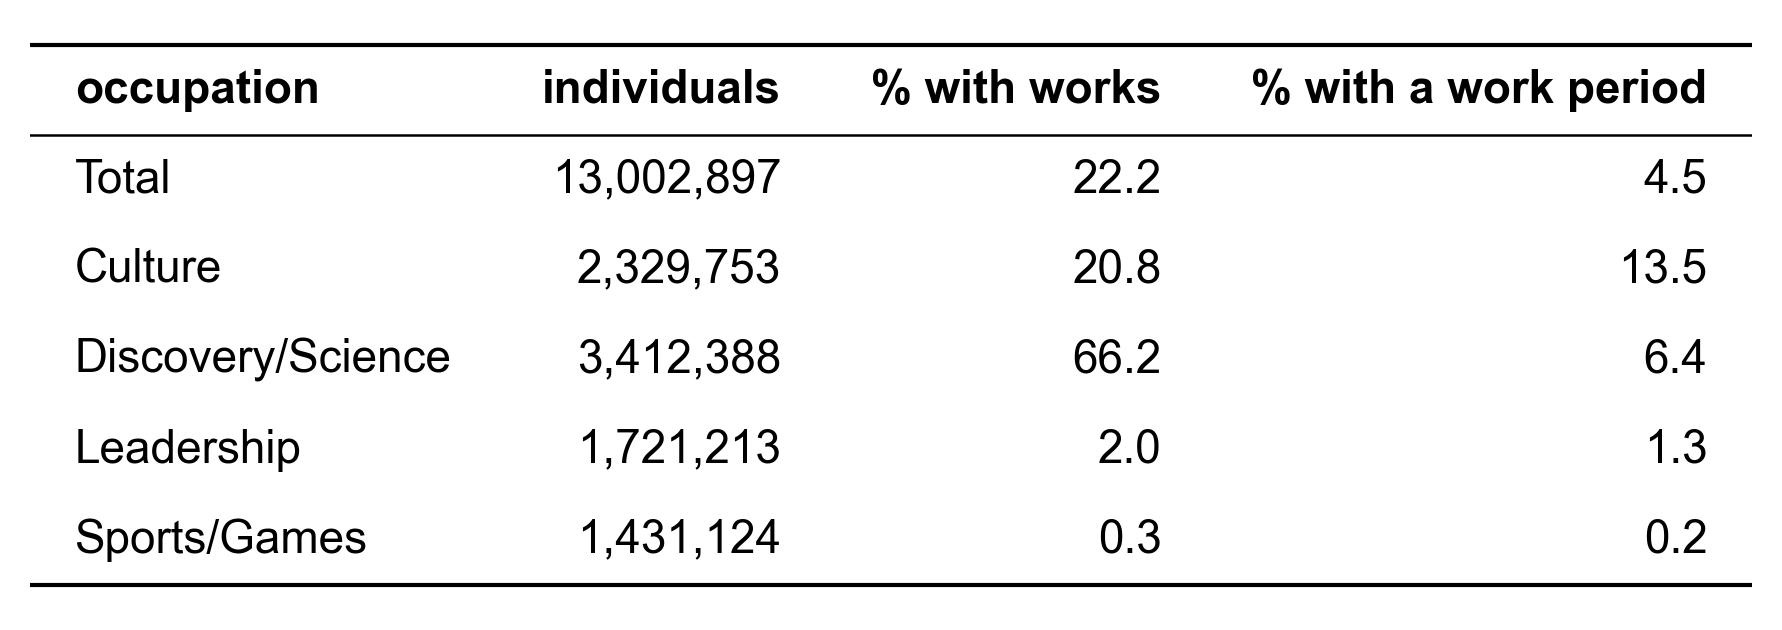

occupation,individuals,% with works,% with a work period
str,u32,f64,f64
"""Total""",13002897,22.229392,4.497352
"""Culture""",2329753,20.765592,13.474304
"""Discovery/Science""",3412388,66.200649,6.409265
"""Leadership""",1721213,1.963267,1.298968
"""Sports/Games""",1431124,0.31332,0.222902


In [8]:
coverage = people.with_columns(pl.col('qid').is_in(periods['qid'].implode()).alias('has_period'))
coverage = pl.concat([coverage.with_columns(pl.lit('Total').alias('occupation')), coverage]).group_by('occupation').agg(
    pl.len().alias('individuals'),
    (100 * pl.col('has_works').mean()).alias('% with works'),
    (100 * pl.col('has_period').mean()).alias('% with a work period'),
).filter(pl.col('occupation') != ALL).sort(pl.col('occupation').replace_strict(['Total', *OCCUPATIONS], list(range(len(OCCUPATIONS) + 1))))
show_table(coverage, decimals=1)
coverage

## Age at first and last work
Learnt from the individuals with a Wikidata birth year from 800 BC to 1950 whose first and last works fall between the ages of 10 and 100, in different years (a single year gives no work period). Each value is the median age in every century of birth with at least 10 individuals, averaged over those centuries (each century weighs the same). Overall covers every individual, with an occupation or not.

279,606 of 584,786 work periods
153,546 with the first and the last work in different years


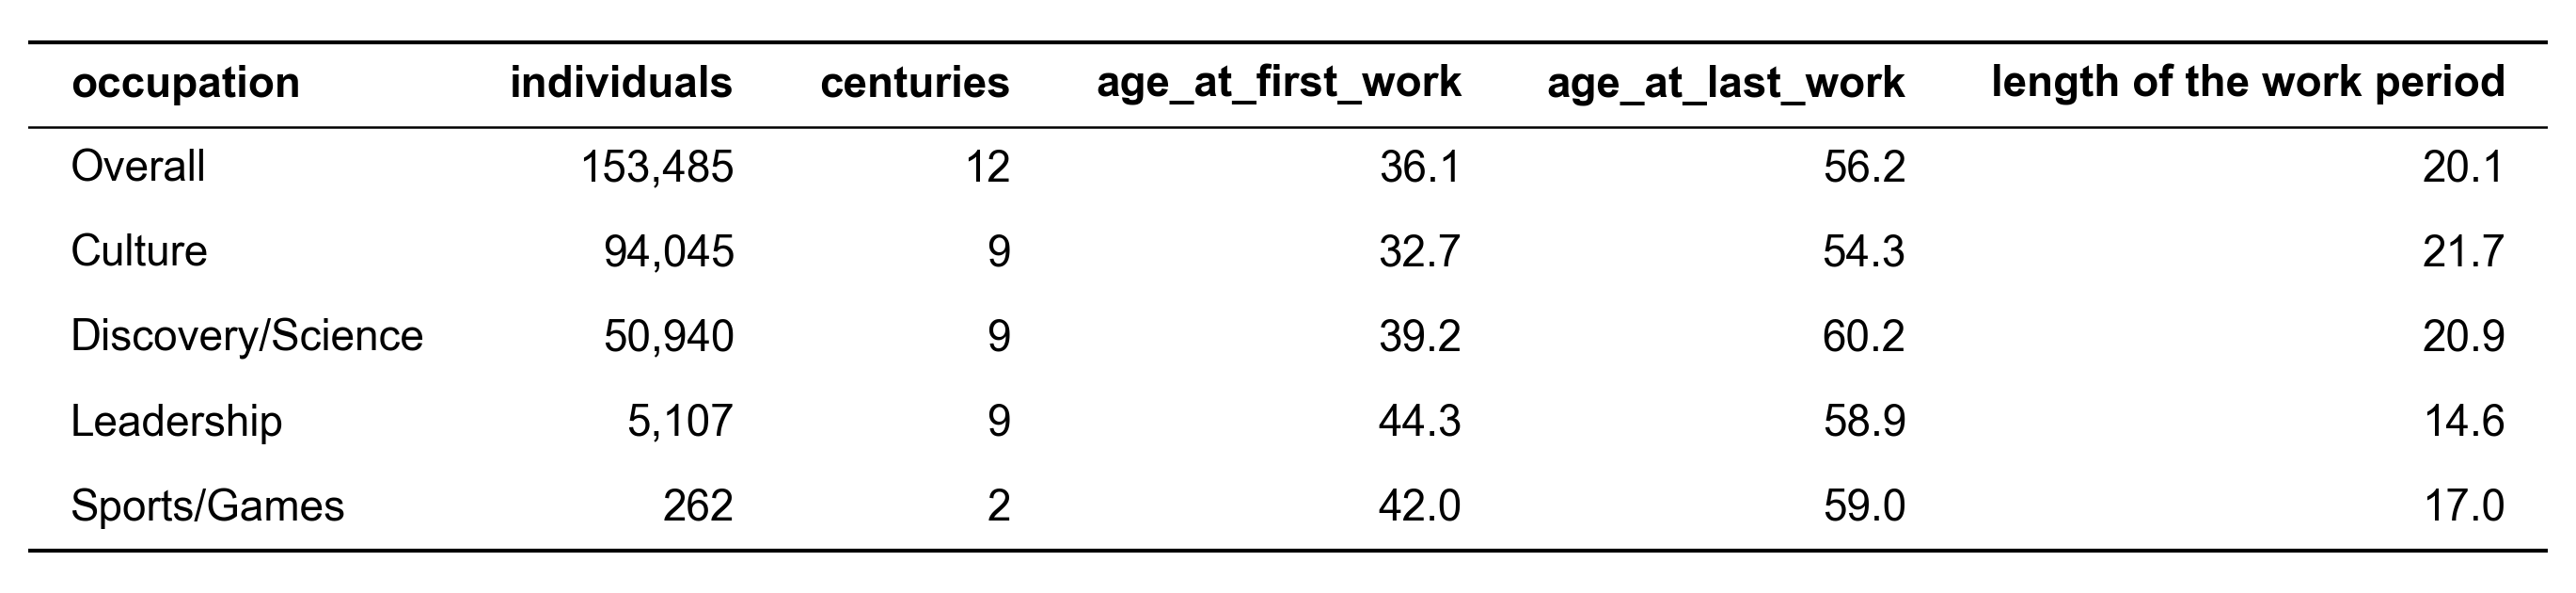

In [9]:
lives = periods.filter(
    pl.col('birth_year').is_between(FIRST_CENTURY, LAST_BIRTH_YEAR)
    & pl.col('age_at_first_work').is_between(*AGE_RANGE)
    & pl.col('age_at_last_work').is_between(*AGE_RANGE)
)
print(f'{lives.height:,} of {periods.height:,} work periods')
lives = lives.filter(pl.col('first_year') < pl.col('last_year'))
print(f'{lives.height:,} with the first and the last work in different years')
AGES = ['age_at_first_work', 'age_at_last_work']


def century_average(frame, by):
    """Median ages in every century of birth with at least MIN_COHORT individuals, averaged over those centuries."""
    return (
        frame.group_by(*by, 'century').agg(pl.len().alias('individuals'), pl.col(AGES).median())
        .filter(pl.col('individuals') >= MIN_COHORT)
        .group_by(by).agg(pl.col('individuals').sum(), pl.len().alias('centuries'), pl.col(AGES).mean())
    )


def spans(frame):
    """Century-averaged ages at the first and the last work: overall (every individual) and for each of the four occupations."""
    return pl.concat([
        century_average(frame.with_columns(pl.lit(OVERALL).alias('occupation')), ['occupation']),
        century_average(frame.filter(pl.col('occupation') != ALL), ['occupation']),
    ]).sort(pl.col('occupation').replace_strict([OVERALL, *OCCUPATIONS], list(range(len(OCCUPATIONS) + 1))))


show_table(spans(lives).with_columns((pl.col('age_at_last_work') - pl.col('age_at_first_work')).alias('length of the work period')), decimals=1)

### Figure X: work period, overall and by occupation
Century-averaged age at the first and at the last work; above, the length of the work period. Overall covers every individual, with an occupation or not.

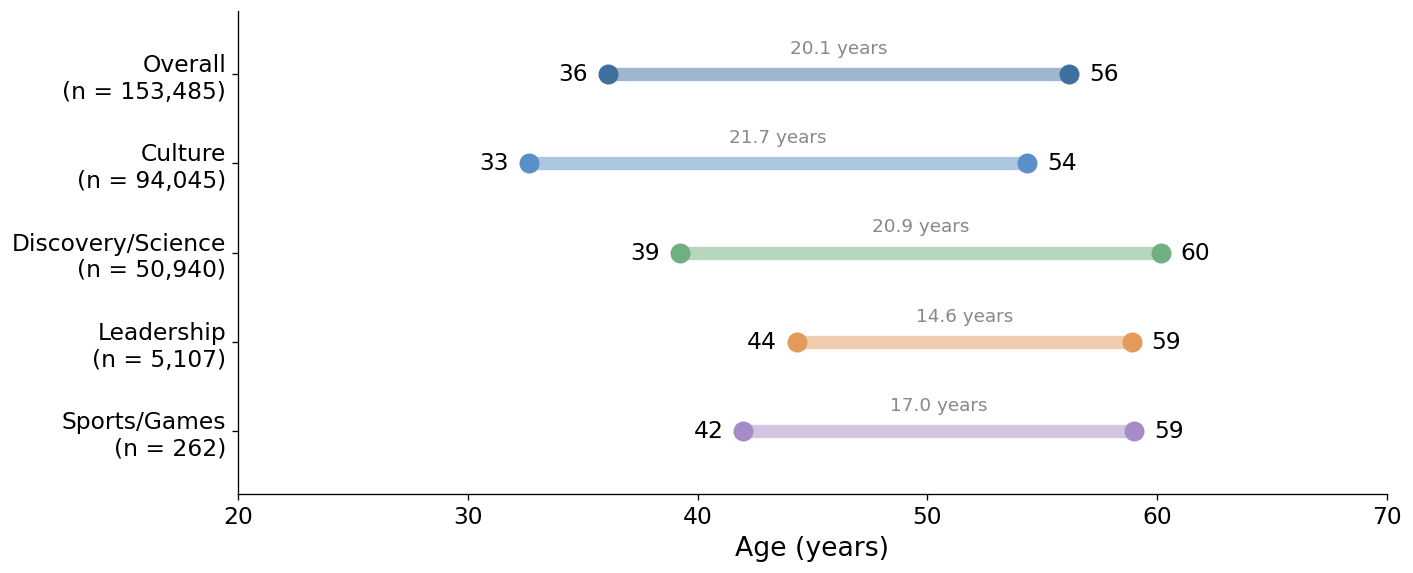

In [10]:
ROW_ORDER = [OVERALL, *OCCUPATIONS]
ROW_COLORS = {OVERALL: MAIN_LINE_COLOR, **OCCUPATION_COLORS}


def draw_span(ax, y, row, color, side=1, hollow=False, show_n=False):
    first, last = row['age_at_first_work'], row['age_at_last_work']
    ax.plot([first, last], [y, y], color=color, linewidth=8, solid_capstyle='round', alpha=0.25 if hollow else 0.5)
    ax.plot([first, last], [y, y], 'o', color=color, markersize=10, markeredgewidth=2, markerfacecolor='white' if hollow else color)
    ax.annotate(f'{first:.0f}', (first, y), xytext=(-12, 0), textcoords='offset points', ha='right', va='center')
    ax.annotate(f'{last:.0f}', (last, y), xytext=(12, 0), textcoords='offset points', ha='left', va='center')
    length = f"{last - first:.1f} years" + (f" (n = {row['individuals']:,})" if show_n else '')
    ax.annotate(length, ((first + last) / 2, y), xytext=(0, 10 * side), textcoords='offset points', ha='center',
                va='bottom' if side > 0 else 'top', color=MUTED_TEXT, fontsize=POINT_LABEL_FONTSIZE)


def finish(ax, labels):
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels[::-1])
    ax.set_ylim(-0.7, len(labels) - 0.3)
    ax.set_xlim(20, 70)
    ax.set_xlabel('Age (years)')
    ax.grid(axis='y', visible=False)
    plt.tight_layout()
    plt.show()


everyone = {row['occupation']: row for row in spans(lives).iter_rows(named=True)}
rows = [group for group in ROW_ORDER if group in everyone]
fig, ax = plt.subplots(figsize=FIGSIZE)
for i, group in enumerate(rows):
    draw_span(ax, len(rows) - 1 - i, everyone[group], ROW_COLORS[group])
finish(ax, [f"{group}\n(n = {everyone[group]['individuals']:,})" for group in rows])

### Figure X: work period, born before and after 1500
Hollow: born before 1500; filled: born from 1500 to 1950. Century-averaged as above.

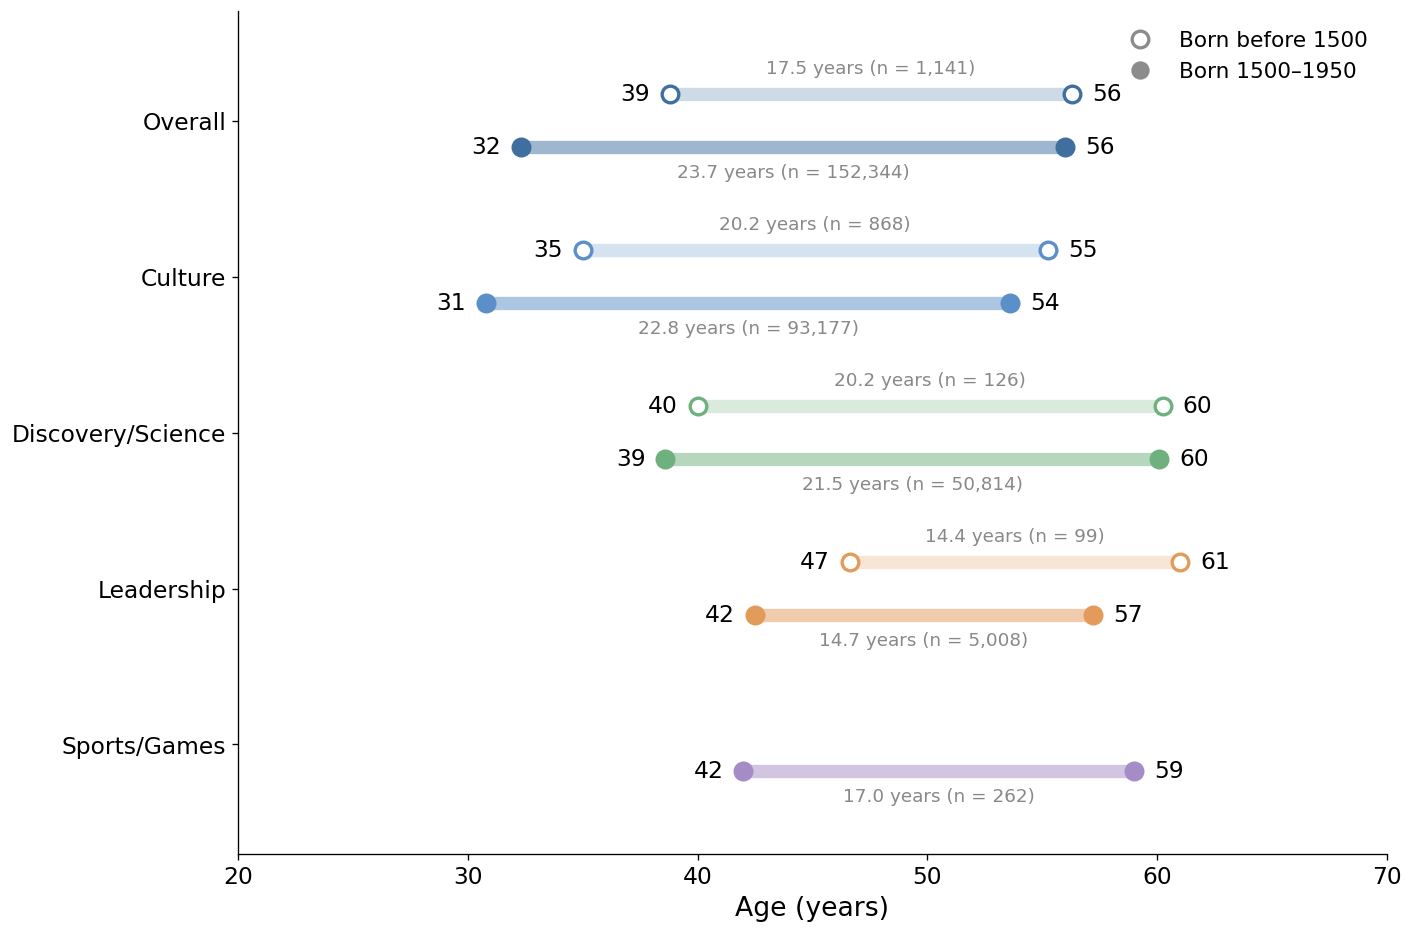

In [11]:
before = {row['occupation']: row for row in spans(lives.filter(pl.col('birth_year') < SPLIT_YEAR)).iter_rows(named=True)}
after = {row['occupation']: row for row in spans(lives.filter(pl.col('birth_year') >= SPLIT_YEAR)).iter_rows(named=True)}
fig, ax = plt.subplots(figsize=(12, 8))
for i, group in enumerate(rows):
    y = len(rows) - 1 - i
    if group in before:
        draw_span(ax, y + 0.17, before[group], ROW_COLORS[group], side=1, hollow=True, show_n=True)
    if group in after:
        draw_span(ax, y - 0.17, after[group], ROW_COLORS[group], side=-1, show_n=True)
ax.plot([], [], 'o', color=GREY, markerfacecolor='white', markeredgewidth=2, markersize=10, label=f'Born before {SPLIT_YEAR}')
ax.plot([], [], 'o', color=GREY, markersize=10, label=f'Born {SPLIT_YEAR}–{LAST_BIRTH_YEAR}')
ax.legend(loc='upper right')
finish(ax, rows)

## Models
Each model imputes the year of the work as birth year + the median age at the work of the individual's cohort: everyone (global), the same century of birth, the same occupation, or both. The global and occupation medians are the century medians averaged over the centuries of birth with at least 10 individuals; a century cohort with fewer than 10 individuals takes the nearest century. The last work is capped at the death year and the first work at the last.

In [12]:
first_century = people['birth_year'].min() // CENTURY * CENTURY
grid = pl.DataFrame({'century': range(first_century, LAST_BIRTH_YEAR // CENTURY * CENTURY + 1, CENTURY)}).join(pl.DataFrame({'occupation': GROUPS}), how='cross')


def cohort_table(lives, measure, model):
    """Median age at the work of the model's cohort, for every century of birth and occupation."""
    keys = MODELS[model]
    stats = [pl.len().alias('cohort_individuals'), pl.col(f'age_at_{measure}_work').median().alias('age')]
    if 'century' not in keys:
        everyone = lives.with_columns(pl.lit(OVERALL).alias('everyone'))
        cohorts = century_average(everyone, keys or ['everyone']).select(*keys, pl.col('individuals').alias('cohort_individuals'), pl.col(f'age_at_{measure}_work').alias('age'))
        table = (grid.join(cohorts, on=keys) if keys else grid.join(cohorts, how='cross')).with_columns(pl.col('century').alias('cohort_century'))
    else:
        cohorts = lives.group_by(keys).agg(*stats).filter(pl.col('cohort_individuals') >= MIN_COHORT).rename({'century': 'cohort_century'})
        others = [key for key in keys if key != 'century']
        table = (
            (grid.join(cohorts, on=others) if others else grid.join(cohorts, how='cross'))
            .sort((pl.col('cohort_century') - pl.col('century')).abs(), 'cohort_century', descending=[False, True])
            .group_by('occupation', 'century', maintain_order=True).first()
        )
    assert table.height == grid.height
    return table


def impute(targets, tables):
    """First and last work = birth year + the cohort's median age, the last no later than the death and the first no later than the last."""
    imputed = targets.select('qid', 'occupation', 'birth_year', 'death_year', *[c for c in ('first_year', 'last_year') if c in targets.columns]).with_columns(
        (pl.col('birth_year') // CENTURY * CENTURY).clip(grid['century'].min(), grid['century'].max()).alias('century')
    )
    for measure, table in tables.items():
        imputed = imputed.join(
            table.select('occupation', 'century', *[pl.col(c).alias(f'{measure}_{c}') for c in ('cohort_century', 'cohort_individuals', 'age')]),
            on=['occupation', 'century'], how='left',
        ).with_columns((pl.col('birth_year') + pl.col(f'{measure}_age').round()).cast(pl.Int64).alias(f'{measure}_from_cohort'))
    imputed = imputed.with_columns(pl.min_horizontal('last_from_cohort', 'death_year').alias('imputed_last_year'))
    imputed = imputed.with_columns(pl.min_horizontal('first_from_cohort', 'imputed_last_year').alias('imputed_first_year'))
    assert imputed.height == targets.height and imputed['imputed_first_year'].null_count() == imputed['imputed_last_year'].null_count() == 0
    return imputed

## Test on a held-out 20%
Each score is computed in every century of birth with at least 10 test individuals, then averaged over those centuries (each century weighs the same).

In [13]:
test = lives.sort('qid').sample(fraction=TEST_SHARE, shuffle=True, seed=SEED)
train = lives.join(test, on='qid', how='anti')
assert train.height + test.height == lives.height
print(f'train: {train.height:,}, test: {test.height:,}')

scores = []
for model in MODELS:
    imputed_test = impute(test, {measure: cohort_table(train, measure, model) for measure in MEASURES})
    row = {'model': model}
    for measure in MEASURES:
        per_century = (
            imputed_test.with_columns((pl.col(f'imputed_{measure}_year') - pl.col(f'{measure}_year')).abs().alias('error'))
            .group_by('century')
            .agg(pl.len().alias('individuals'), pl.col('error').mean().alias('error'), (100 * (pl.col('error') <= WITHIN).mean()).alias('within'))
            .filter(pl.col('individuals') >= MIN_COHORT)
        )
        row[f'{measure} work: mean absolute error'] = per_century['error'].mean()
        row[f'{measure} work: % within {WITHIN} years'] = per_century['within'].mean()
    scores.append(row)
scores = pl.DataFrame(scores)
BEST = {measure: scores.sort(f'{measure} work: % within {WITHIN} years', descending=True)['model'][0] for measure in MEASURES}
print(f"best model, age at first work: {BEST['first']}; age at last work: {BEST['last']}")

train: 122,837, test: 30,709
best model, age at first work: median by century of birth × occupation; age at last work: median by century of birth × occupation


### % of the held-out 20% imputed within 10 years [mean absolute error, in years], averaged over centuries of birth

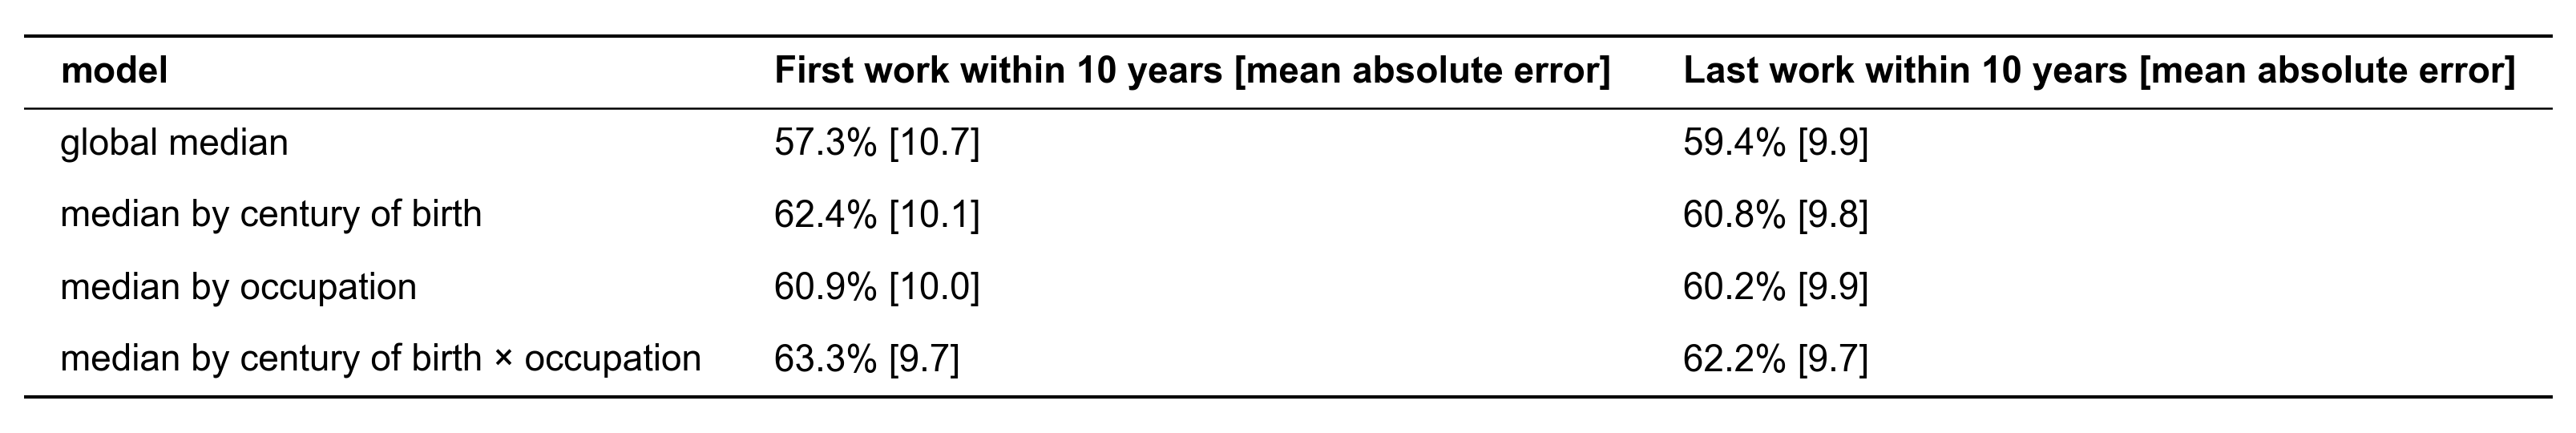

In [14]:
show_table(scores.select('model', *[
    pl.format('{}% [{}]', pl.col(f'{measure} work: % within {WITHIN} years').round(1), pl.col(f'{measure} work: mean absolute error').round(1))
    .alias(f'{measure.capitalize()} work within {WITHIN} years [mean absolute error]')
    for measure in MEASURES
]))

## Imputation
For individuals with no work period and a Wikidata birth year up to 1950, each age with its best model, learnt on all the work periods.

In [15]:
tables = {measure: cohort_table(lives, measure, BEST[measure]) for measure in MEASURES}
targets = people.join(periods, on='qid', how='anti').filter(pl.col('birth_year') <= LAST_BIRTH_YEAR)
imputed = impute(targets, tables)
pl.DataFrame([{
    'imputed': measure,
    'model': BEST[measure],
    'individuals': imputed.height,
    'from the nearest century': imputed.filter(pl.col(f'{measure}_cohort_century') != pl.col('century')).height,
    'capped': imputed.filter(pl.col(f'imputed_{measure}_year') != pl.col(f'{measure}_from_cohort')).height,
    'average age used': round(imputed[f'{measure}_age'].mean(), 1),
} for measure in MEASURES])

imputed,model,individuals,from the nearest century,capped,average age used
str,str,i64,i64,i64,f64
"""first""","""median by century of birth × o…",3950902,100292,243367,40.7
"""last""","""median by century of birth × o…",3950902,100292,667227,59.4


### Imputed work period of the best-known individual of each century of birth
Among the individuals with no dated work.

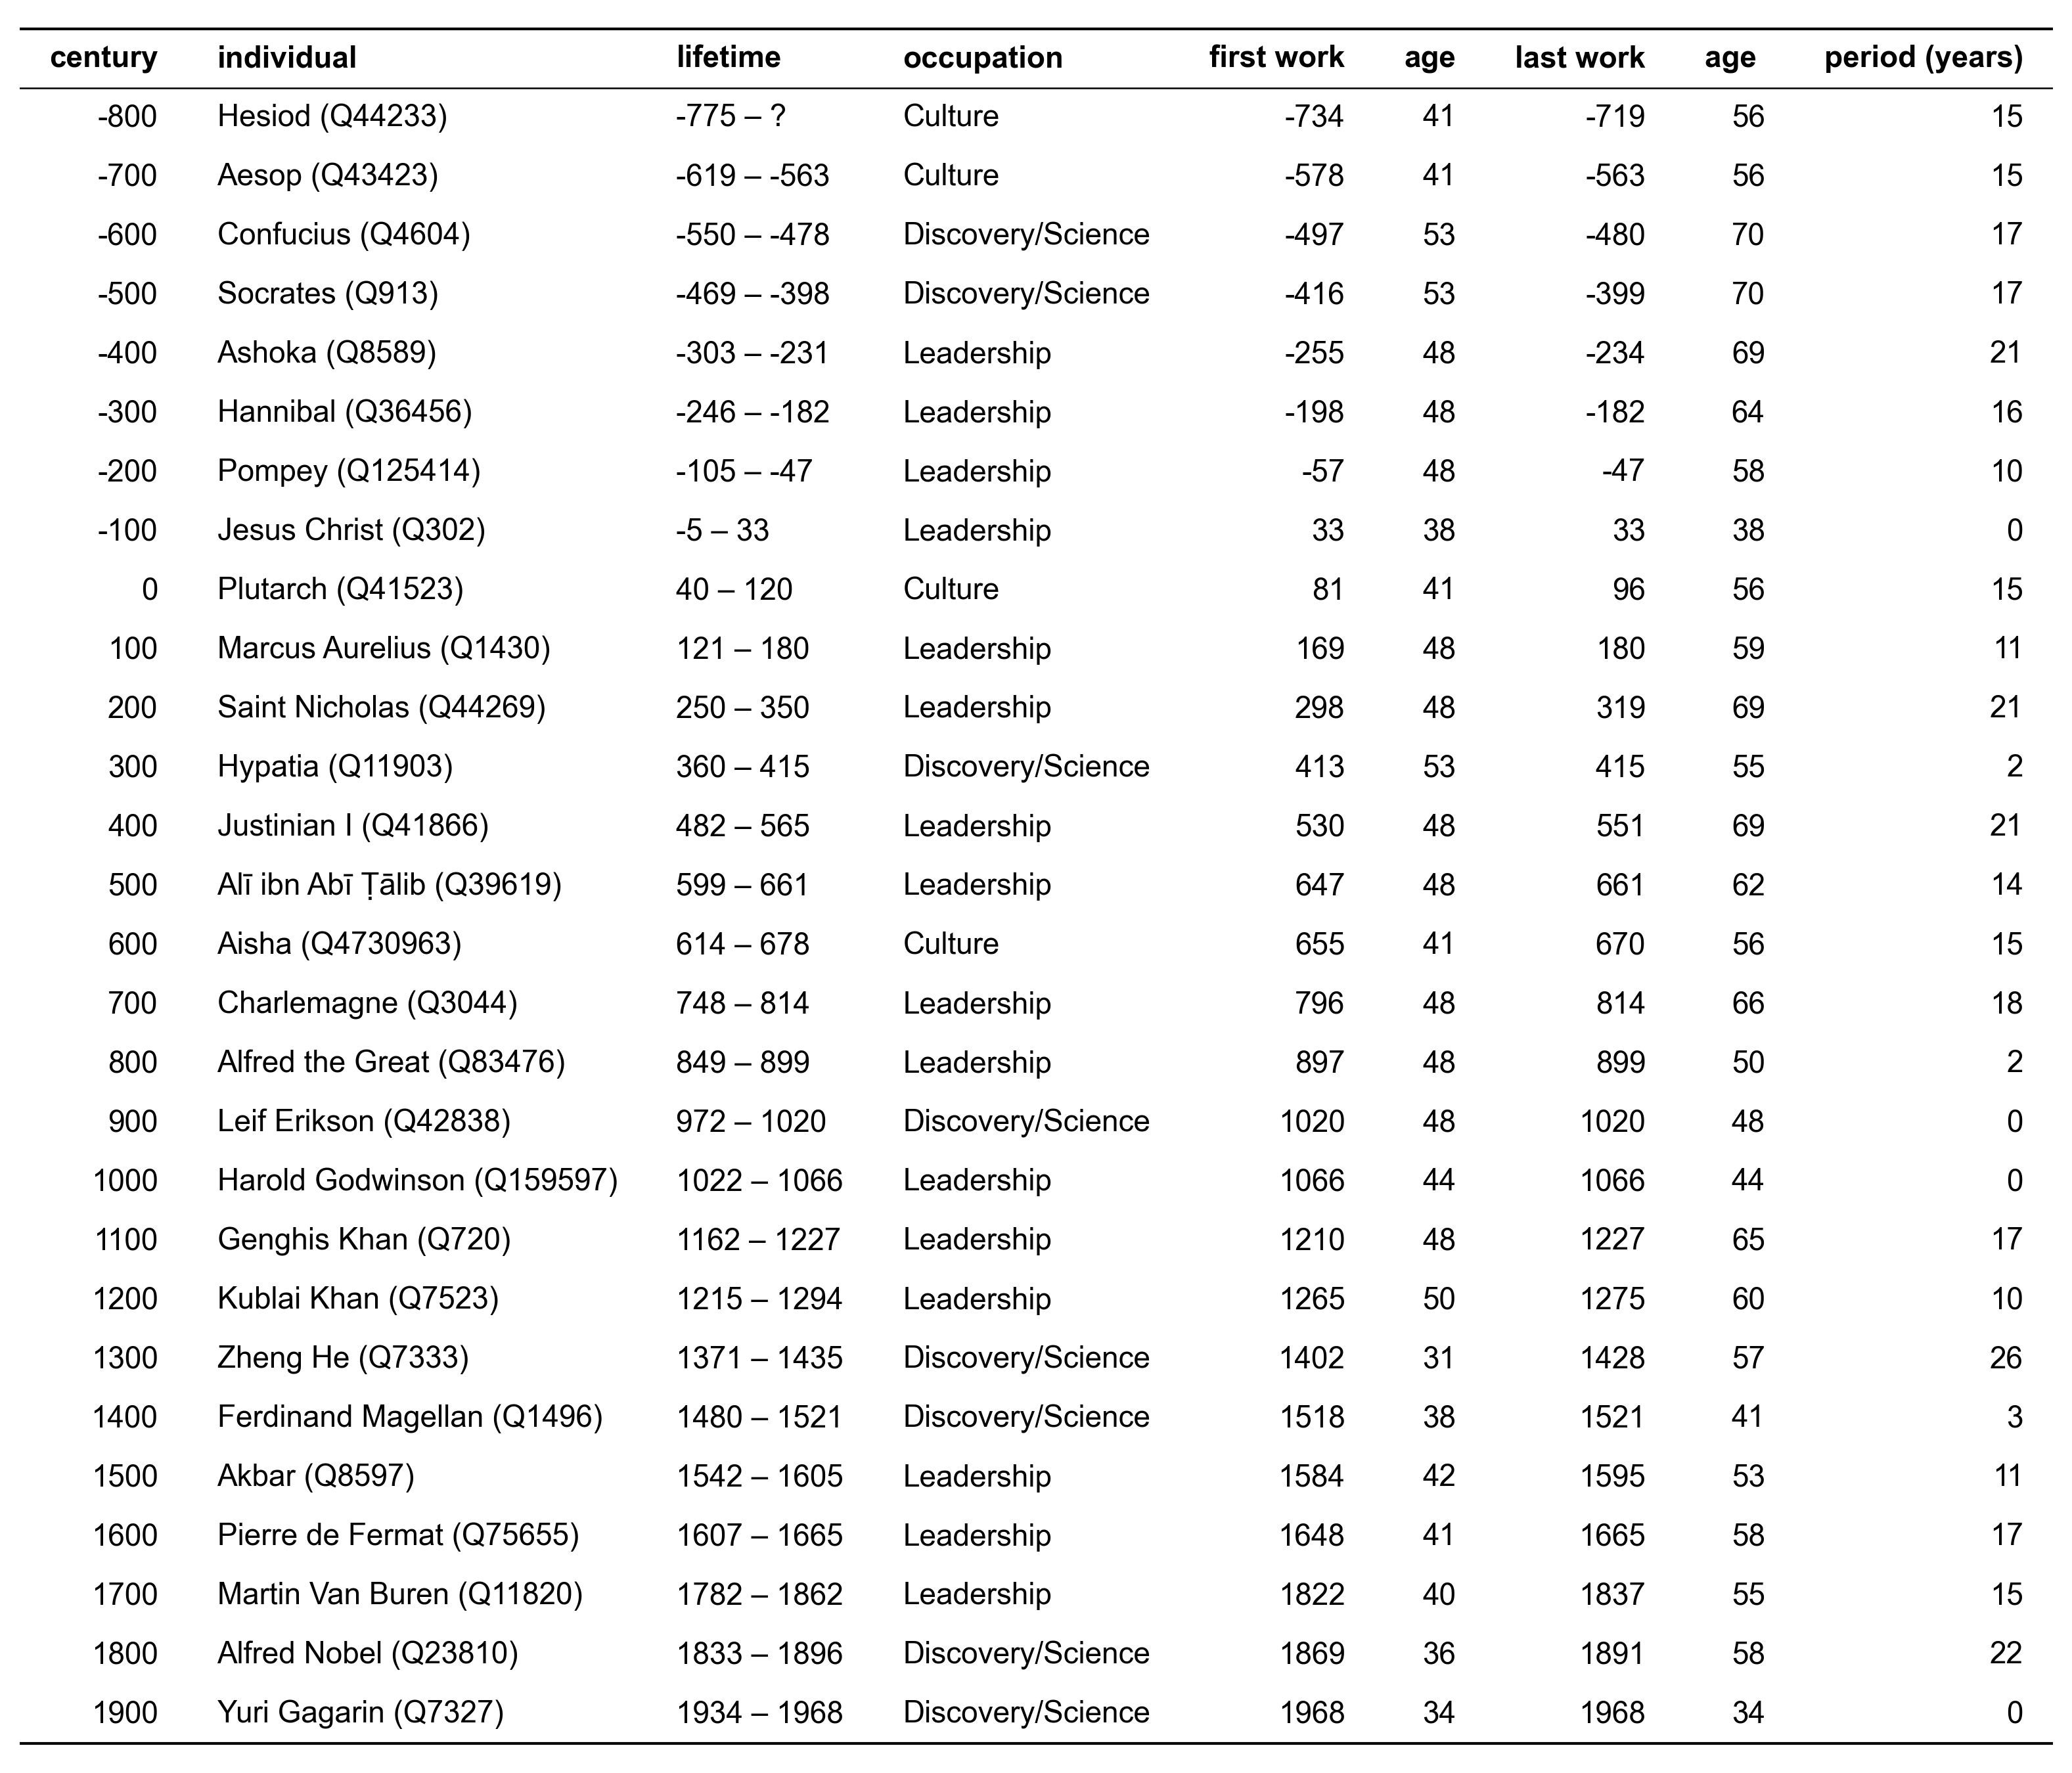

In [16]:
imputed_examples = best_known_per_century(imputed.with_columns((pl.col('birth_year') // CENTURY * CENTURY).alias('century')))
show_table(imputed_examples.select(
    *individual_columns(),
    'occupation',
    pl.col('imputed_first_year').cast(pl.String).alias('first work'),
    (pl.col('imputed_first_year') - pl.col('birth_year')).alias('age'),
    pl.col('imputed_last_year').cast(pl.String).alias('last work'),
    (pl.col('imputed_last_year') - pl.col('birth_year')).alias('age '),
    (pl.col('imputed_last_year') - pl.col('imputed_first_year')).alias('period (years)'),
))

## Save
One row per individual with `IndividualEnriched.first_work_date` and `last_work_date`: the dates read from the dated works (`source = 'dated works'`), else the imputed ones (`source = 'estimated'`, with the `cohort` used); `field_provenance` gives the rule.

In [17]:
sys.path.insert(0, '../../scripts/1-datamodels')
sys.path.insert(0, '../../scripts/3-raw_to_db/helpers')
import datamodel_in_duckdb as D
from pydantic_to_duckdb_schema import duck_type

DATE_TYPE = duck_type(D.IndividualDate)
INPUTS = ['Individual.work', 'Work.inception', 'Work.publication_date', 'Individual.birth_date', 'Individual.death_date', 'Occupation.meta_occupation']
OBSERVED_RULE = (
    f'From the dated works: the earliest or the latest work date, a work dated by its inception, else its publication, precise to the year or the decade '
    f'(a decade counting as its middle year), inside the lifetime (birth to death, or within {LIFETIME} years of a single birth or death), '
    f'without the publication-only individuals with no birth or death, nor their publications over {LIFETIME} years from their earliest inception, nor the individuals whose inceptions span over {LIFETIME} years; '
    f'the age is the year minus the Wikidata birth year.'
)


def estimated_rule(measure):
    keys = MODELS[BEST[measure]]
    group = pl.lit('individuals')
    if 'occupation' in keys:
        group = pl.when(pl.col('occupation') == ALL).then(pl.lit('individuals with no occupation')).otherwise(pl.col('occupation') + ' individuals')
    born = pl.lit(f', averaged over their centuries of birth with at least {MIN_COHORT} individuals,')
    if 'century' in keys:
        born = pl.format(' born in {}–{}', f'{measure}_cohort_century', pl.col(f'{measure}_cohort_century') + CENTURY - 1)
        born = pl.when(pl.col(f'{measure}_cohort_century') != pl.col('century')).then(pl.format('{}, the nearest century with at least {} of them', born, pl.lit(MIN_COHORT))).otherwise(born)
    cap = 'the death year' if measure == 'last' else 'the estimated last work'
    capped = pl.when(pl.col(f'imputed_{measure}_year') != pl.col(f'{measure}_from_cohort')).then(pl.lit(f', capped at {cap}')).otherwise(pl.lit(''))
    return pl.format(f'Estimated from the age at {measure} work: the Wikidata birth year + {{}} years, the median age at {measure} work of the {{}} {{}}{{}} with a work period ({BEST[measure]}){{}}.',
                     pl.col(f'{measure}_age').round(1), f'{measure}_cohort_individuals', group, born, capped)


def cohort(measure):
    keys = MODELS[BEST[measure]]
    return pl.struct(
        (pl.when(pl.col('occupation') != ALL).then('occupation') if 'occupation' in keys else pl.lit(None, pl.String)).alias('occupation'),
        (pl.col(f'{measure}_cohort_century') if 'century' in keys else pl.lit(None, pl.Int64)).alias('century'),
        pl.col(f'{measure}_cohort_individuals').cast(pl.Int64).alias('individuals'),
        pl.col(f'{measure}_age').cast(pl.Float64).alias('age'),
    ).alias(f'{measure}_cohort')


works_periods = pl.concat([
    periods.select('qid', 'first_year', 'last_year', pl.lit('dated works').alias('source'),
                   pl.lit(OBSERVED_RULE).alias('first_rule'), pl.lit(OBSERVED_RULE).alias('last_rule')),
    imputed.select('qid', pl.col('imputed_first_year').alias('first_year'), pl.col('imputed_last_year').alias('last_year'), pl.lit('estimated').alias('source'),
                   estimated_rule('first').alias('first_rule'), estimated_rule('last').alias('last_rule'), cohort('first'), cohort('last')),
], how='diagonal')
assert works_periods['qid'].is_unique().all()
con.register('works_periods', works_periods.to_arrow())


def work_date(measure):
    provenance = f"{{'raw': [], 'inputs': $inputs, 'rule': works_periods.{measure}_rule, 'ai_answer': NULL, 'retrieved_on': NULL}}"
    return f"""CASE WHEN works_periods.qid IS NOT NULL THEN CAST({{'iso': NULL, 'year': works_periods.{measure}_year,
        'precision': CASE WHEN works_periods.source = 'estimated' THEN 'year' END,
        'field_provenance': MAP {{'year': {provenance}}}, 'source': works_periods.source, 'cohort': works_periods.{measure}_cohort}} AS {DATE_TYPE}) END AS {measure}_work_date"""


WORK_DATES = f"""
    SELECT individual.entity.qid AS qid, {work_date('first')}, {work_date('last')}
    FROM individual
    LEFT JOIN works_periods ON works_periods.qid = individual.entity.qid
"""
con.sql(f"SELECT * FROM ({WORK_DATES}) WHERE first_work_date.source = 'estimated' LIMIT 4", params={'inputs': INPUTS}).pl()

qid,first_work_date,last_work_date
str,struct[6],struct[6]
"""Q102199670""","{null,1980,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""Estimated from the age at first work: the Wikidata birth year + 47.0 years, the median age at first work of the 2245 individuals with no occupation born in 1900–1999 with a work period (median by century of birth × occupation)."",null,null}}],""estimated"",{null,1900,2245,47.0}}","{null,2000,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""Estimated from the age at last work: the Wikidata birth year + 67.0 years, the median age at last work of the 2245 individuals with no occupation born in 1900–1999 with a work period (median by century of birth × occupation)."",null,null}}],""estimated"",{null,1900,2245,67.0}}"
"""Q102199704""","{null,1964,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""Estimated from the age at first work: the Wikidata birth year + 41.0 years, the median age at first work of the 37093 Discovery/Science individuals born in 1900–1999 with a work period (median by century of birth × occupation)."",null,null}}],""estimated"",{""Discovery/Science"",1900,37093,41.0}}","{null,1995,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""Estimated from the age at last work: the Wikidata birth year + 72.0 years, the median age at last work of the 37093 Discovery/Science individuals born in 1900–1999 with a work period (median by century of birth × occupation)."",null,null}}],""estimated"",{""Discovery/Science"",1900,37093,72.0}}"
"""Q102199735""","{null,1991,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""Estimated from the age at first work: the Wikidata birth year + 41.0 years, the median age at first work of the 37093 Discovery/Science individuals born in 1900–1999 with a work period (median by century of birth × occupation)."",null,null}}],""estimated"",{""Discovery/Science"",1900,37093,41.0}}","{null,2022,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""Estimated from the age at last work: the Wikidata birth year + 72.0 years, the median age at last work of the 37093 Discovery/Science individuals born in 1900–1999 with a work period (median by century of birth × occupation)."",null,null}}],""estimated"",{""Discovery/Science"",1900,37093,72.0}}"
"""Q102199821""","{null,1974,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""Estimated from the age at first work: the Wikidata birth year + 47.0 years, the median age at first work of the 2245 individuals with no occupation born in 1900–1999 with a work period (median by century of birth × occupation)."",null,null}}],""estimated"",{null,1900,2245,47.0}}","{null,1994,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""Estimated from the age at last work: the Wikidata birth year + 67.0 years, the median age at last work of the 2245 individuals with no occupation born in 1900–1999 with a work period (median by century of birth × occupation)."",null,null}}],""estimated"",{null,1900,2245,67.0}}"


In [18]:
if SAVE:
    OUTPUT_PATH.parent.mkdir(exist_ok=True)
    con.execute(f"COPY ({WORK_DATES} ORDER BY qid) TO '{OUTPUT_PATH}' (FORMAT parquet)", {'inputs': INPUTS})
    saved = con.sql(f"SELECT count(*) AS individuals, count(*) FILTER (first_work_date.source = 'dated works') AS from_dated_works, count(*) FILTER (first_work_date.source = 'estimated') AS estimated FROM '{OUTPUT_PATH}'").pl()
    assert saved['from_dated_works'][0] == periods.height and saved['estimated'][0] == imputed.height
    display(saved)